# TQH-05 — Chắt lọc insight và visual storytelling cho hai User Stories
**T0304 · ETT_GRID_VIS_2026 v2.0 · seed 2026**

Mọi Action Title được tính từ artifacts, không chép con số demo hoặc gán nguyên nhân.
Notebook độc lập với notebook 02: Run-all không phụ thuộc trạng thái kernel trước.
Historical analytics, không dự báo trực tiếp hoặc chứng nhận an toàn thiết bị.
85/95°C là quy ước dự án. Các biểu đồ tiền tính chỉ tham chiếu scope đã lưu.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "AGENTS.md").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.constants import (
    SEED, CADENCE_MINUTES, EXPECTED_DATASET_ROWS, MEASUREMENTS,
    LOAD_BRANCHES, DRY_MONTHS, DAY_NAMES, WARNING_TEMP_THRESHOLD,
    CRITICAL_TEMP_THRESHOLD,
)
assert SEED == 2026
random.seed(SEED)
np.random.seed(SEED)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 95, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": False,
                     "font.size": 10})
NAVY, TEAL, SLATE = "#1E3A8A", "#0D9488", "#64748B"
AMBER, CRIMSON, GRID = "#D97706", "#DC2626", "#E2E8F0"
audit = json.loads((ROOT / "audit/t0205_artifacts_sync_audit.json").read_text(encoding="utf-8"))
assert audit["status"] == "PASS"
names = ["clean_ett.parquet", "load_profiles_stl.parquet", "quantile_bands.parquet",
         "lag_correlation_matrix.json", "thermal_breach_events.parquet", "loess_curves.parquet"]
source_hashes = {}
for name in names:
    path = ROOT / ("data/processed" if name == "clean_ett.parquet" else "output/artifacts") / name
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == audit["artifacts"][name]["sha256_bytes"], f"Stale audit: {name}"
    source_hashes[name] = digest
clean = pd.read_parquet(ROOT / "data/processed/clean_ett.parquet")
profiles = pd.read_parquet(ROOT / "output/artifacts/load_profiles_stl.parquet")
bands = pd.read_parquet(ROOT / "output/artifacts/quantile_bands.parquet")
lag = json.loads((ROOT / "output/artifacts/lag_correlation_matrix.json").read_text(encoding="utf-8"))
events = pd.read_parquet(ROOT / "output/artifacts/thermal_breach_events.parquet")
curves = pd.read_parquet(ROOT / "output/artifacts/loess_curves.parquet")
assert clean.groupby("dataset").size().to_dict() == EXPECTED_DATASET_ROWS
assert not clean.duplicated(["dataset", "timestamp"]).any()
data = clean.copy()
data["hour"] = data.timestamp.dt.hour
data["weekday"] = data.timestamp.dt.dayofweek
data["month"] = data.timestamp.dt.month
data["season"] = np.where(data.month.isin(DRY_MONTHS), "Dry", "Wet")
datasets = sorted(CADENCE_MINUTES)
gap_counts = {}
for dataset, group in data.groupby("dataset"):
    delta = group.timestamp.diff().dropna()
    cadence = pd.Timedelta(minutes=CADENCE_MINUTES[dataset])
    assert (delta >= cadence).all() and (delta % cadence == pd.Timedelta(0)).all()
    gap_counts[dataset] = int(delta.gt(cadence).sum())
assert gap_counts == audit["quality_audit"]["gap_counts"]
display(pd.DataFrame({"samples": clean.groupby("dataset").size(),
                      "cadence_minutes": pd.Series(CADENCE_MINUTES),
                      "observed_gaps": pd.Series(gap_counts)}))
print("Interpreter:", sys.executable)
print("Seed:", SEED, "| timezone: unknown | read-only audited inputs: six")

,samples,cadence_minutes,observed_gaps
ETTh1,17420,60,0
ETTh2,17420,60,0
ETTm1,69680,15,0


Interpreter: f:\Study Materials\specialized_subject\Visualization\Visualization_gr\data_visualization_project\.venv\Scripts\python.exe
Seed: 2026 | timezone: unknown | read-only audited inputs: six


## 1. What–Why–How: dữ liệu → tác vụ → encoding/interaction

| User Story | What | Why | How / interaction trong dashboard |
|---|---|---|---|
| US-01: kế hoạch tải | OT theo ngày, giờ, nhóm tháng | Tìm chu kỳ, so sánh giai đoạn để hỗ trợ lập lịch | Calendar Heatmap; dataset/season/date filter; tooltip giữ °C |
| US-01: tải và nhiệt | STL và hourly quantile bands | Phân biệt trend/chu kỳ và độ phân tán lịch sử | STL panels; Fan 50/80/95%; median riêng mean; shared time context |
| US-01: tỷ trọng tải | Cặp useful/unuseful ở từng cấp áp | So sánh cơ cấu, nhận diện dữ liệu không hợp lệ | **100% Stacked Bar**, không Stacked Area; loại tỷ trọng âm/mẫu số ≤0, không clip |
| US-01: độ trễ | Lag matrix 6×13 theo mùa | Sàng lọc liên hệ tải đi trước nhiệt | Heatmap tâm 0, tooltip n/r/k; không kết luận nhân quả |
| US-02: đối chiếu ngưỡng | OT gốc, ngưỡng 85/95 và events | Tìm mốc vượt ngưỡng và áp lực nhiệt | Threshold line + Barcode/Rug; selection theo khoảng hỗ trợ |
| US-02: khoanh vùng giả thuyết | Sáu tải và tọa độ LOWESS | Đối chiếu nhánh cùng thời gian và quan hệ phi tuyến | Synchronized Small Multiples + scatter/LOESS; zoom shared X trong dashboard |

Các hình dưới là **bản tĩnh nghiên cứu**, không tự nhận có brush/linked selection
như dashboard tương tác. Không chồng bảy đường khác đơn vị vào một trục y.

In [2]:
title_rows = []
peak_rows = []
for dataset, group in data.groupby("dataset"):
    peak = group.loc[group.OT.idxmax()]
    count85 = int(group.OT.ge(WARNING_TEMP_THRESHOLD).sum())
    peak_rows.append({"dataset": dataset, "peak_ot": float(peak.OT), "timestamp": peak.timestamp})
    title_rows.append({"dataset": dataset, "story": "US-02", "chart": "Threshold line",
                       "action_title": f"{dataset}: OT đạt {peak.OT:.2f}°C tại {peak.timestamp}; {count85} mẫu ≥85°C",
                       "evidence": "observed maximum + threshold sample count; no causal attribution"})
    sub = bands.loc[bands.dataset.eq(dataset) & bands.variable.eq("OT") & bands.season.eq("Dry")]
    widest = sub.assign(iqr=sub.q75 - sub.q25).sort_values("iqr", ascending=False).iloc[0]
    title_rows.append({"dataset": dataset, "story": "US-01", "chart": "Hourly Fan / Dry",
                       "action_title": f"{dataset}, Dry: IQR OT rộng nhất {widest.q75-widest.q25:.2f}°C lúc {int(widest.hour):02d}h",
                       "evidence": "max empirical IQR over 24 bins; ties use existing hour order"})
    daily = group.set_index("timestamp").OT.resample("D").mean()
    title_rows.append({"dataset": dataset, "story": "US-01", "chart": "Calendar",
                       "action_title": f"{dataset}: OT trung bình ngày cao nhất {daily.max():.2f}°C vào {daily.idxmax().date()}",
                       "evidence": "daily mean; not instantaneous peak"})
    for threshold in [85, 95]:
        ev = events.loc[events.dataset.eq(dataset) & events.threshold_c.eq(threshold)]
        title_rows.append({"dataset": dataset, "story": "US-02", "chart": f"Events ≥{threshold}°C",
                           "action_title": f"{dataset}: {len(ev)} đợt ≥{threshold}°C; {ev.duration_hours.sum():.2f}h và {ev.degree_hours.sum():.2f}°C·h",
                           "evidence": "saved event support; each threshold separately"})
action_titles = pd.DataFrame(title_rows)
display(action_titles[["dataset", "chart", "action_title"]])
assert not action_titles.action_title.str.contains("do quán tính", regex=False).any()

,dataset,chart,action_title
0,ETTh1,Threshold line,ETTh1: OT đạt 46.01°C tại 2016-07-29 15:00:00;...
1,ETTh1,Hourly Fan / Dry,"ETTh1, Dry: IQR OT rộng nhất 7.44°C lúc 14h"
2,ETTh1,Calendar,ETTh1: OT trung bình ngày cao nhất 41.44°C vào...
3,ETTh1,Events ≥85°C,ETTh1: 0 đợt ≥85°C; 0.00h và 0.00°C·h
4,ETTh1,Events ≥95°C,ETTh1: 0 đợt ≥95°C; 0.00h và 0.00°C·h
5,ETTh2,Threshold line,ETTh2: OT đạt 58.88°C tại 2017-07-28 15:00:00;...
6,ETTh2,Hourly Fan / Dry,"ETTh2, Dry: IQR OT rộng nhất 12.27°C lúc 15h"
7,ETTh2,Calendar,ETTh2: OT trung bình ngày cao nhất 49.94°C vào...
8,ETTh2,Events ≥85°C,ETTh2: 0 đợt ≥85°C; 0.00h và 0.00°C·h
9,ETTh2,Events ≥95°C,ETTh2: 0 đợt ≥95°C; 0.00h và 0.00°C·h


## 2. US-01 — Ngày đáng chú ý và dải giờ lịch sử
Calendar nghiên cứu dạng tháng × ngày; ô không có quan sát giữ masked (không tô 0).
Màu OT dùng thang tuyệt đối chung, không gán Critical cho percentile cao của OT thấp.
Fan chọn Dry như một tham chiếu có nhãn; không xem là refit theo Date Range.

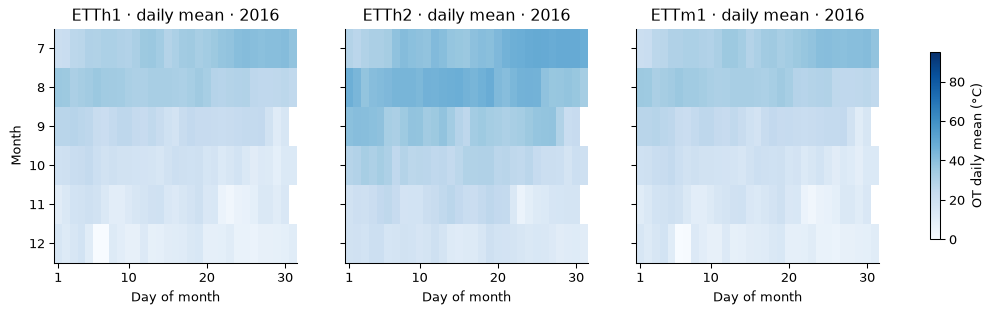

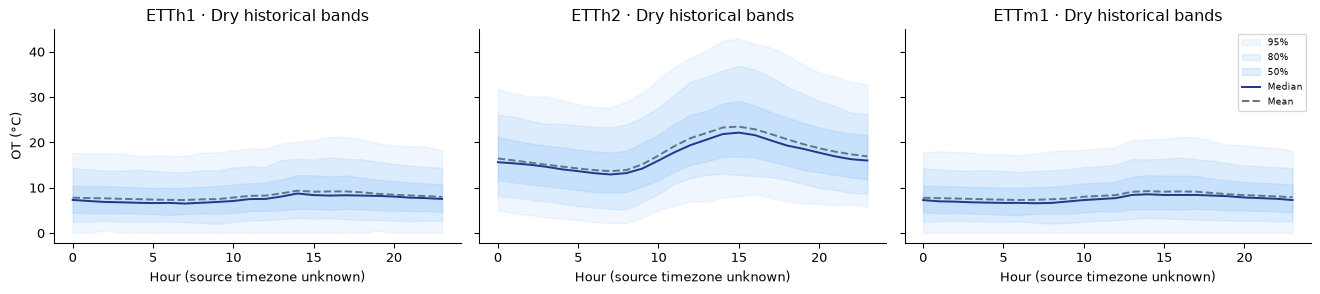

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, dataset in zip(axes, datasets):
    daily = data.loc[data.dataset.eq(dataset)].set_index("timestamp").OT.resample("D").mean().dropna()
    selected_year = int(daily.index.year.min())
    selected = daily.loc[daily.index.year == selected_year]
    matrix = pd.DataFrame({"month": selected.index.month, "day": selected.index.day, "OT": selected.values}).pivot(index="month", columns="day", values="OT")
    image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()), aspect="auto", cmap="Blues", vmin=0, vmax=95)
    ax.set(title=f"{dataset} · daily mean · {selected_year}", xlabel="Day of month")
    ax.set_xticks([0, 9, 19, 29], [1, 10, 20, 30])
    ax.set_yticks(range(len(matrix.index)), matrix.index)
axes[0].set_ylabel("Month")
fig.colorbar(image, ax=axes, label="OT daily mean (°C)", shrink=0.8)
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, dataset in zip(axes, datasets):
    sub = bands.loc[bands.dataset.eq(dataset) & bands.variable.eq("OT") & bands.season.eq("Dry")].sort_values("hour")
    for low, high, label, alpha in [("q025", "q975", "95%", .14), ("q10", "q90", "80%", .20), ("q25", "q75", "50%", .28)]:
        ax.fill_between(sub.hour, sub[low], sub[high], color="#93C5FD", alpha=alpha, label=label)
    ax.plot(sub.hour, sub.q50, color=NAVY, label="Median")
    ax.plot(sub.hour, sub["mean"], color=SLATE, ls="--", label="Mean")
    ax.set(title=f"{dataset} · Dry historical bands", xlabel="Hour (source timezone unknown)")
axes[0].set_ylabel("OT (°C)"); axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Cơ cấu useful/unuseful theo từng cấp áp
Tính tỷ lệ từng mẫu hợp lệ rồi lấy mean theo giờ; không lấy tỷ lệ hai tổng một
cách ngầm định. Mẫu âm/null hoặc tổng ≤0 bị loại, không `.clip(lower=0)`.
Useful/unuseful là nhãn nguồn, chưa đồng nhất với P/Q đã hiệu chuẩn.

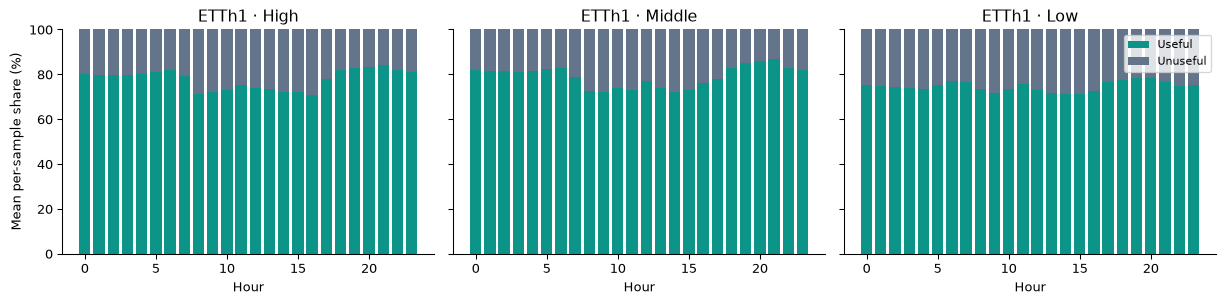

,dataset,tier,excluded_samples,valid_samples
0,ETTh1,High,4585,12835
1,ETTh1,Middle,7312,10108
2,ETTh1,Low,1728,15692


In [4]:
selected_dataset = datasets[0]
group = data.loc[data.dataset.eq(selected_dataset)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
share_evidence = []
for ax, (tier, useful, unuseful) in zip(axes, [("High", "HUFL", "HULL"), ("Middle", "MUFL", "MULL"), ("Low", "LUFL", "LULL")]):
    total = group[useful] + group[unuseful]
    valid = group[useful].ge(0) & group[unuseful].ge(0) & total.gt(0)
    ratio = (group[useful] / total).where(valid)
    hourly = ratio.groupby(group.hour).mean().reindex(range(24))
    ax.bar(hourly.index, 100 * hourly, color=TEAL, label="Useful")
    ax.bar(hourly.index, 100 * (1-hourly), bottom=100 * hourly, color=SLATE, label="Unuseful")
    ax.set(title=f"{selected_dataset} · {tier}", xlabel="Hour", ylim=(0,100))
    share_evidence.append({"dataset": selected_dataset, "tier": tier, "excluded_samples": int((~valid).sum()), "valid_samples": int(valid.sum())})
axes[0].set_ylabel("Mean per-sample share (%)"); axes[-1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(share_evidence))

### Lag heatmap: chỉ sàng lọc liên hệ lịch sử
Chọn Pearson/Dry và báo cả n. Tối đa |r| trên nhiều ô là thống kê mô tả,
không phải kiểm định nguyên nhân hoặc ước lượng quán tính thiết bị đã hiệu chuẩn.

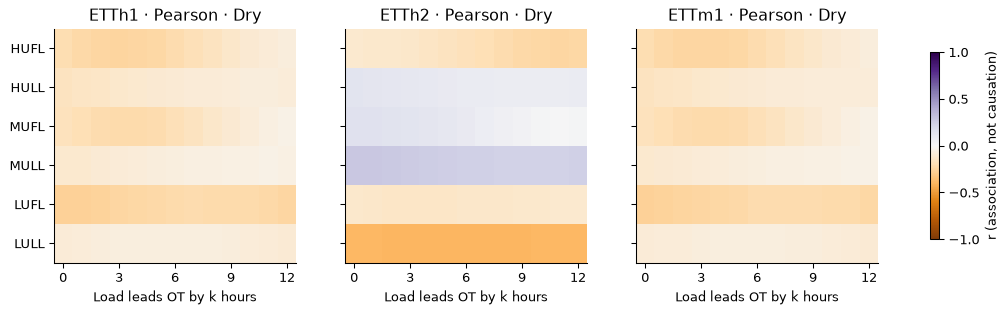

,dataset,load,lag_h,r,paired_n
0,ETTh1,LUFL,0,-0.271,8688
1,ETTh2,LULL,5,-0.401,8688
2,ETTm1,LUFL,0,-0.266,34752


**Action Title:** ETTh1, Dry: |r| lớn nhất tại LUFL, lag 0h, r=-0.271, n=8688 — chỉ là liên hệ lịch sử.

**Action Title:** ETTh2, Dry: |r| lớn nhất tại LULL, lag 5h, r=-0.401, n=8688 — chỉ là liên hệ lịch sử.

**Action Title:** ETTm1, Dry: |r| lớn nhất tại LUFL, lag 0h, r=-0.266, n=34752 — chỉ là liên hệ lịch sử.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
lag_insights = []
for ax, dataset in zip(axes, datasets):
    record = next(r for r in lag["records"] if r["dataset"] == dataset and r["season"] == "Dry" and r["method"] == "pearson")
    matrix = np.array(record["correlation_matrix"], dtype=float)
    image = ax.imshow(np.ma.masked_invalid(matrix), aspect="auto", cmap="PuOr", vmin=-1, vmax=1)
    ax.set(title=f"{dataset} · Pearson · Dry", xlabel="Load leads OT by k hours")
    ax.set_xticks([0, 3, 6, 9, 12]); ax.set_yticks(range(6), LOAD_BRANCHES)
    if np.isfinite(matrix).any():
        branch, hour = np.unravel_index(np.nanargmax(np.abs(matrix)), matrix.shape)
        n = record["sample_counts"][branch][hour]
        lag_insights.append({"dataset": dataset, "load": LOAD_BRANCHES[branch], "lag_h": int(hour), "r": matrix[branch,hour], "paired_n": n})
fig.colorbar(image, ax=axes, label="r (association, not causation)", shrink=0.8)
plt.show(); display(pd.DataFrame(lag_insights).round(3))
for item in lag_insights:
    display(Markdown(f"**Action Title:** {item['dataset']}, Dry: |r| lớn nhất tại {item['load']}, "
                     f"lag {item['lag_h']}h, r={item['r']:.3f}, n={item['paired_n']} — chỉ là liên hệ lịch sử."))

## 3. US-02 — Ngưỡng và barcode/rug sự kiện
Vẽ OT quan sát đầy đủ, không nối chéo dataset. Bảng events rỗng hợp lệ được
thông báo trực tiếp; không nâng nhiệt demo hoặc vẽ barcode giả.

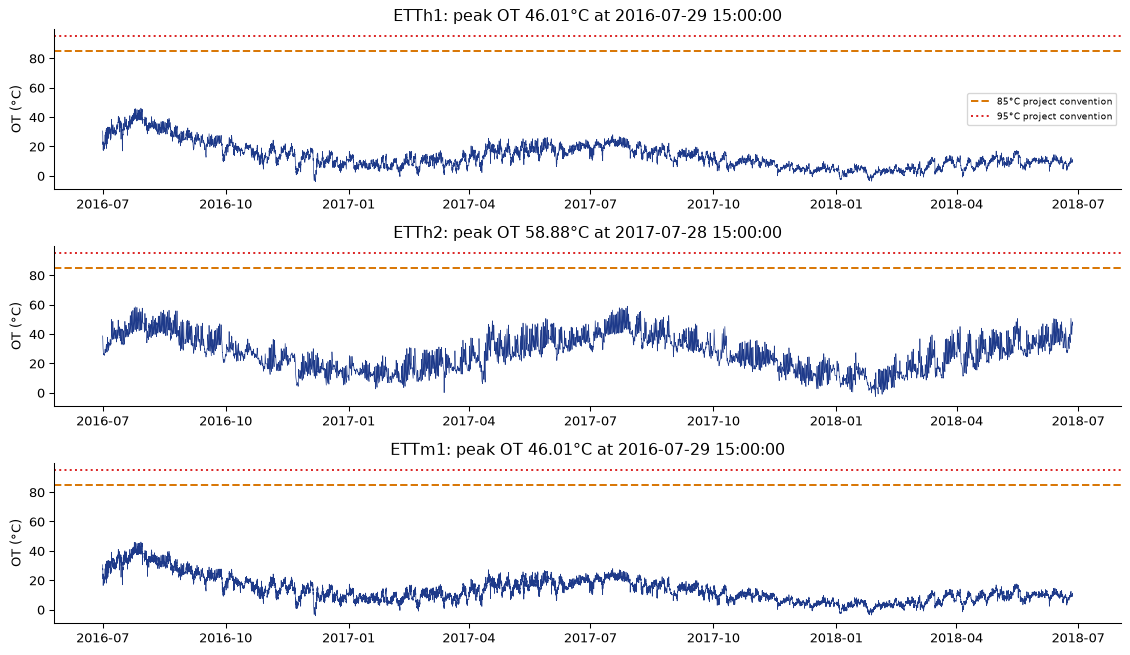

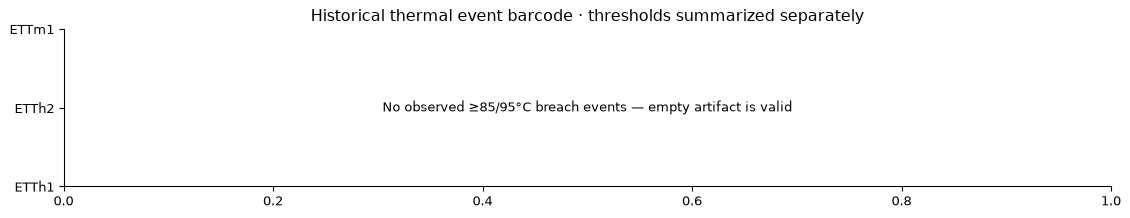

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharey=True)
for ax, dataset in zip(axes, datasets):
    group = data.loc[data.dataset.eq(dataset)]
    ax.plot(group.timestamp, group.OT, color=NAVY, lw=0.5)
    ax.axhline(85, color=AMBER, ls="--", label="85°C project convention")
    ax.axhline(95, color=CRIMSON, ls=":", label="95°C project convention")
    peak = group.loc[group.OT.idxmax()]
    ax.set(title=f"{dataset}: peak OT {peak.OT:.2f}°C at {peak.timestamp}", ylabel="OT (°C)")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(12, 2.4))
for index, dataset in enumerate(datasets):
    for event in events.loc[events.dataset.eq(dataset)].itertuples():
        ax.plot([event.start_timestamp, event.end_timestamp], [index,index], lw=5,
                color=CRIMSON if event.threshold_c == 95 else AMBER)
ax.set_yticks(range(3), datasets)
if events.empty:
    ax.text(.5,.5,"No observed ≥85/95°C breach events — empty artifact is valid",
            ha="center", va="center", transform=ax.transAxes)
ax.set_title("Historical thermal event barcode · thresholds summarized separately")
plt.tight_layout(); plt.show()

### Sáu nhánh tải và LOWESS đã lưu
Small multiples dùng cùng X và daily mean để đọc bối cảnh; không phải view
chẩn đoán sự cố từng mẫu. Không có breach thật nên không tự gán “thủ phạm”.
Scatter dùng mẫu thưa xác định **chỉ để hiển thị**, LOESS là tọa độ artifact fit
trên toàn bộ cặp hợp lệ, scope all/ALL; không fit bằng Statsmodels trong notebook này.

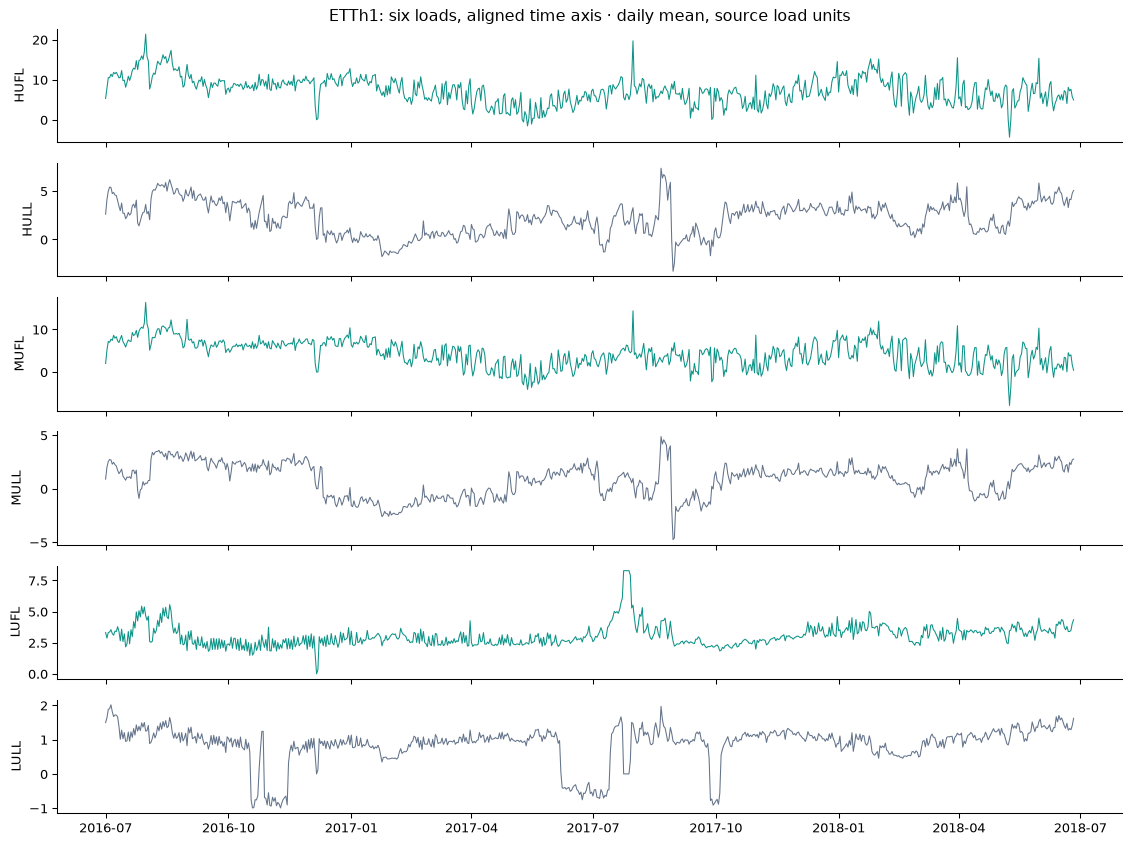

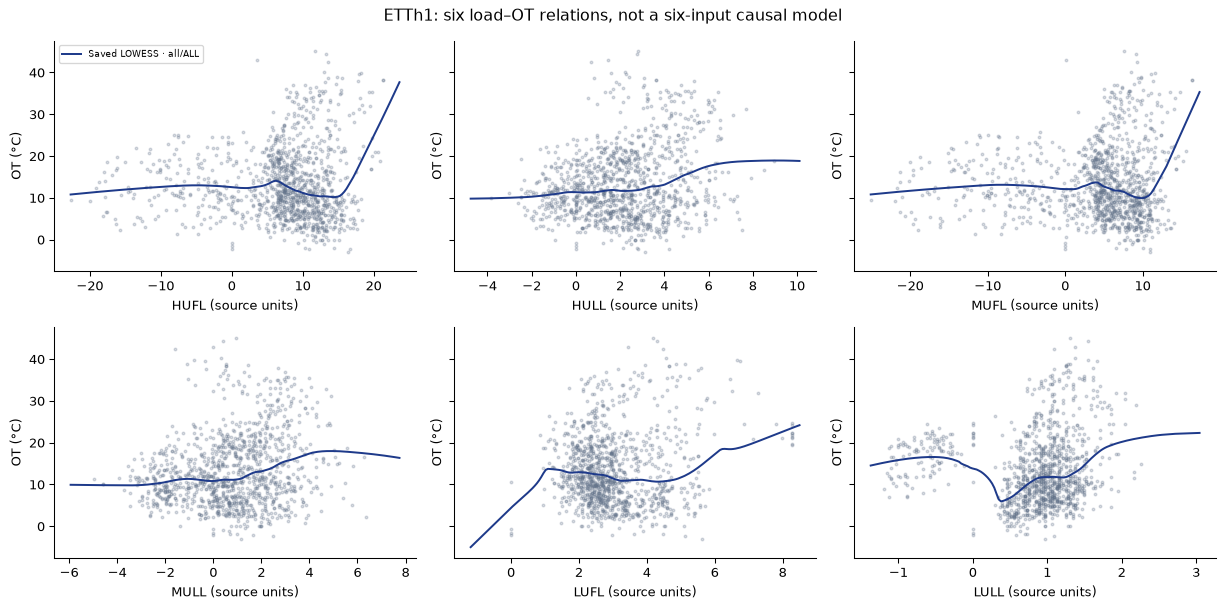

In [7]:
group = data.loc[data.dataset.eq(selected_dataset)].copy()
daily_loads = group.set_index("timestamp")[list(LOAD_BRANCHES)].resample("D").mean()
fig, axes = plt.subplots(6, 1, figsize=(12, 9), sharex=True)
for ax, variable in zip(axes, LOAD_BRANCHES):
    ax.plot(daily_loads.index, daily_loads[variable], color=TEAL if variable in ["HUFL", "MUFL", "LUFL"] else SLATE, lw=.8)
    ax.set_ylabel(variable)
axes[0].set_title(f"{selected_dataset}: six loads, aligned time axis · daily mean, source load units")
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, variable in zip(axes.flat, LOAD_BRANCHES):
    sampled = group.iloc[::max(1, int(np.ceil(len(group)/1200)))]
    ax.scatter(sampled[variable], sampled.OT, color=SLATE, s=4, alpha=.25)
    reference = curves.loc[curves.dataset.eq(selected_dataset) & curves.load_feature.eq(variable)
                           & curves.scope_type.eq("all") & curves.scope_value.eq("ALL")].sort_values("x_load")
    if reference.empty:
        ax.text(.5,.5,"Offline reference unavailable", transform=ax.transAxes, ha="center")
    else:
        ax.plot(reference.x_load, reference.y_ot_smooth, color=NAVY, label="Saved LOWESS · all/ALL")
    ax.set(xlabel=f"{variable} (source units)", ylabel="OT (°C)")
axes.flat[0].legend(fontsize=7)
fig.suptitle(f"{selected_dataset}: six load–OT relations, not a six-input causal model")
plt.tight_layout(); plt.show()

## 4. Insight → hành động thận trọng, giả định và giới hạn
- **US-01:** Dùng giờ/tháng có mean/IQR khác biệt làm đầu mối xem xét lịch tải,
  kiểm tra tiếp khả năng vận hành; không ra lệnh điều độ chỉ từ thống kê mô tả.
- **US-02:** Không có breach trong cửa sổ nguồn không chứng minh thiết bị an toàn
  trong tương lai hoặc ngưỡng dự án phù hợp mọi thiết bị.
- Không chép “98,4°C do quán tính tải 3h”: vừa là số liệu chưa xác minh vừa gán nhân quả.
- Timestamps timezone unknown: giờ hiển thị là giờ nguồn, không tự gọi UTC/local.
- Gap counts=0 theo T0205 không loại trừ missing ngoài cửa sổ, sai cảm biến hay biến bị bỏ sót.
- Khác cadence/số mẫu làm so sánh pooled sai lệch; giữ dataset riêng ở mọi chart.
- Thermal event ≥95 có thể nằm trong ≥85: duration/Degree-Hours tổng hợp từng ngưỡng.
- Bands/lag/LOWESS là historical references theo scope lưu, không CI/prediction intervals.
- Static figures không chứng nhận browser interaction, accessibility hay SLA <2s.
- T0304 không sửa engine/core scripts hoặc artifact nguồn; notebooks là sản phẩm nghiên cứu.